# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

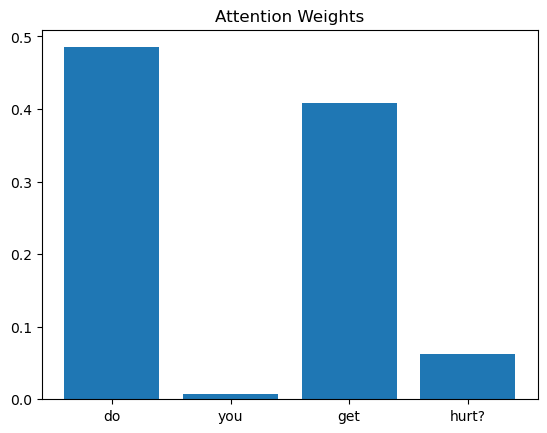

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

**mostly yes, but not always.**

since i used random to choese the word for me in most runs the model puts the bulk of its weight on the **content word** that identifies the topic, these are exactly the words we would use to decide which answer is correct, so the attention looks sensible. but attention is only trained to help **classify**, not to be human-readable. so it might mistakingly put more weight on *are* or *who* insted of ignoring them as they are function words.

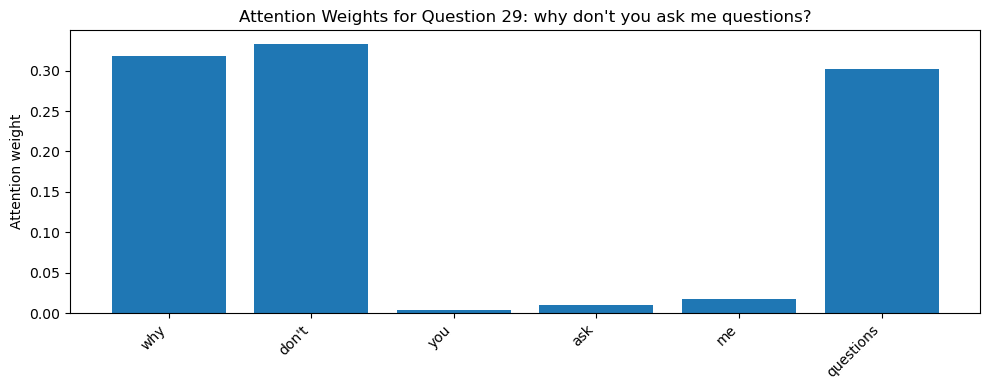

Question 29: why don't you ask me questions?
Highest-attention word: don't (0.3333)



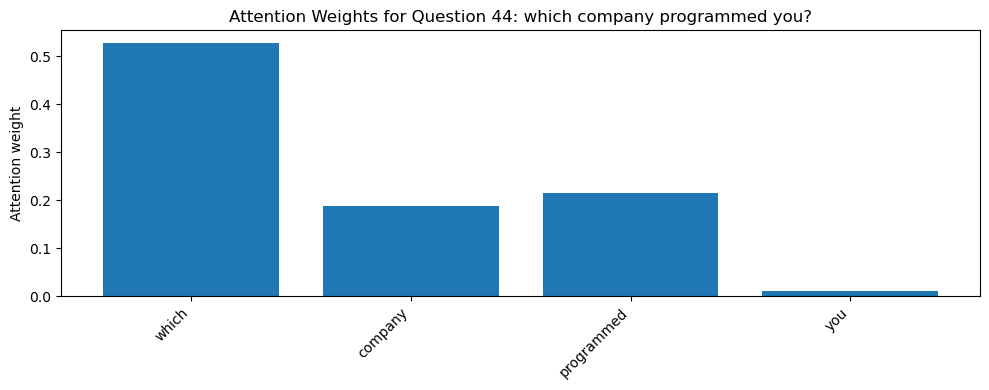

Question 44: which company programmed you?
Highest-attention word: which (0.5271)



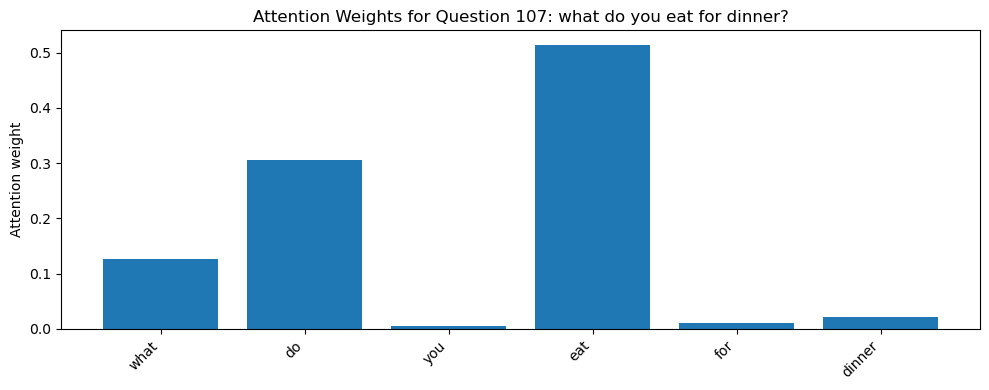

Question 107: what do you eat for dinner?
Highest-attention word: eat (0.5146)



In [7]:
import random
num = random.sample(range(len(df)), 3) 
def get_attention(i):
    question = df["question"][i]
    words = [tokenizer.index_word[n] for n in tokenizer.texts_to_sequences([question])[0]]  # same words the model sees

    with torch.no_grad():
        prediction, weights = model(X[i:i + 1])
   
    attention = weights[0, :len(words)].squeeze().tolist()
    max_index = attention.index(max(attention))

    return {
        "question": question,
        "words": words,
        "attention": attention,
        "highest_word": words[max_index],
        "highest_weight": attention[max_index],
        "answer_id": int(y[i]),
        "predicted": int(prediction.argmax(1)),
    }

for i in random.sample(range(len(df)), 3):
    r = get_attention(i)

    plt.figure(figsize=(10, 4))
    plt.bar(r["words"], r["attention"])
    plt.xticks(rotation=45, ha="right")
    plt.title(f"Attention Weights for Question {i}: {r['question']}")
    plt.ylabel("Attention weight")
    plt.tight_layout()
    plt.show()

    print(f"Question {i}: {r['question']}")
    print(f"Highest-attention word: {r['highest_word']} ({r['highest_weight']:.4f})\n")

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

**pair 1: "how long have you been around?" (25) vs "how long ago were you born?" (27)**
both questions are predicted as answer 1. the highest-attention word is **different**: *been* in the first question and *born* in the second, the two questions share only the words *how long*, and the model focuses on a different word in each.

**pair 2: "who wrote your lines?" (47) vs "who is your designer?" (50)**
both questions are predicted as answer 3. the highest-attention word is **different**: *wrote* and *designer*. these are two different words for the same idea, and the model focuses on each one in its own question.

**pair 3: "which company programmed you?" (44) vs "which company made you?" (53)**
both questions are predicted as answer 3. the highest-attention word is the **same**: *company*. both questions use the word *company*, and the model focuses on it in both.

**What this suggests about attention**

1. In all three pairs the model gives the **same answer** to both questions, in pairs 1 and 2 it focuses on **different words**, and in pair 3 it focuses on the **same word**.
2. Attention works on **words (tokens)**, not on meaning directly. *been* and *born*, or *wrote* and *designer*, are different words, so each gets its own weight.
3. When the questions share a key word (*company*), the attention is also similar. So similar attention mostly reflects shared vocabulary, not shared meaning.
4. The highest-attention word is not always the most meaningful one for a person, so the attention shows **where the model looks** to make its prediction, but it is not a full explanation of what the model understands.

Comparison of two similar questions:
Question 25: how long have you been around?
  answer_id = 1, predicted = 2
Highest-attention word: around (0.9575)

Question 27: how long ago were you born?
  answer_id = 1, predicted = 3
Highest-attention word: born (0.5088)




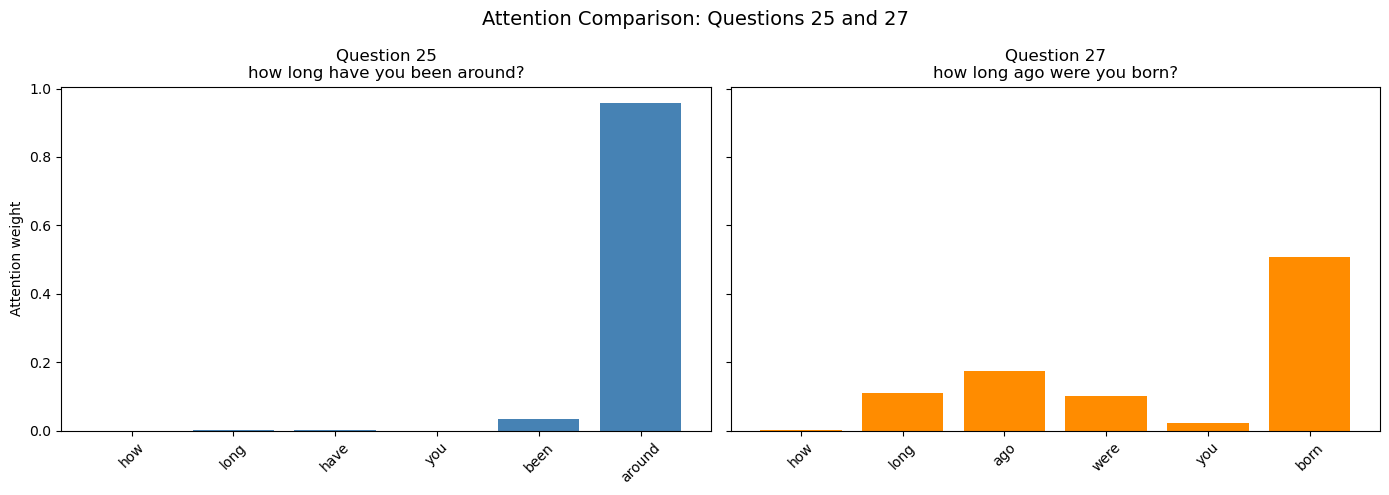

Comparison of two similar questions:
Question 47: who wrote your lines?
  answer_id = 3, predicted = 3
Highest-attention word: lines (0.8051)

Question 50: who is your designer?
  answer_id = 3, predicted = 2
Highest-attention word: designer (0.8308)




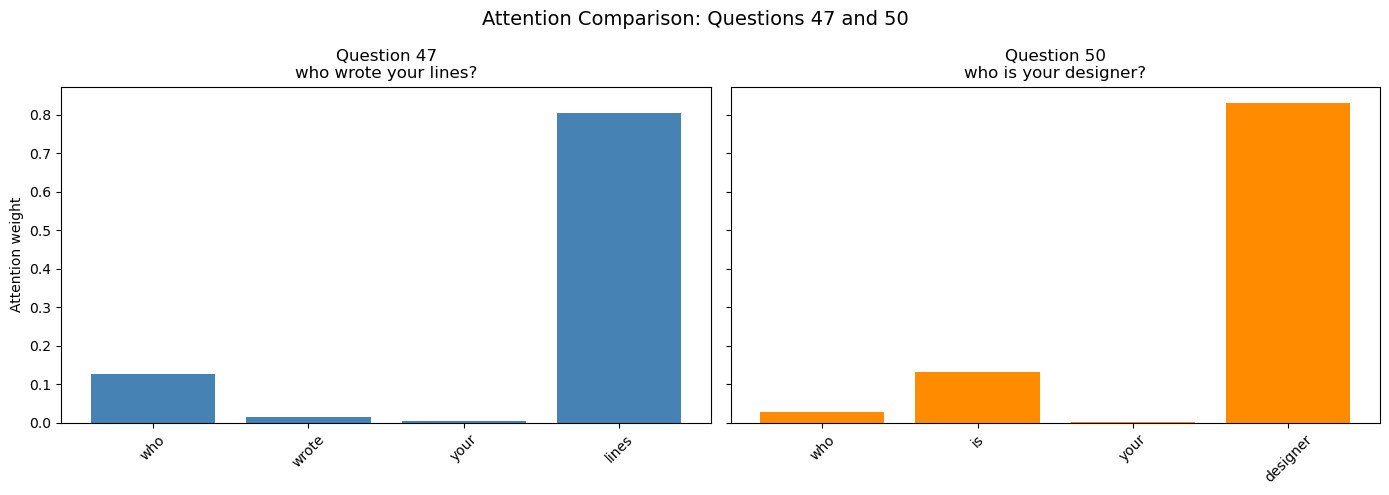

Comparison of two similar questions:
Question 44: which company programmed you?
  answer_id = 3, predicted = 3
Highest-attention word: which (0.5271)

Question 53: which company made you?
  answer_id = 3, predicted = 3
Highest-attention word: which (0.5262)




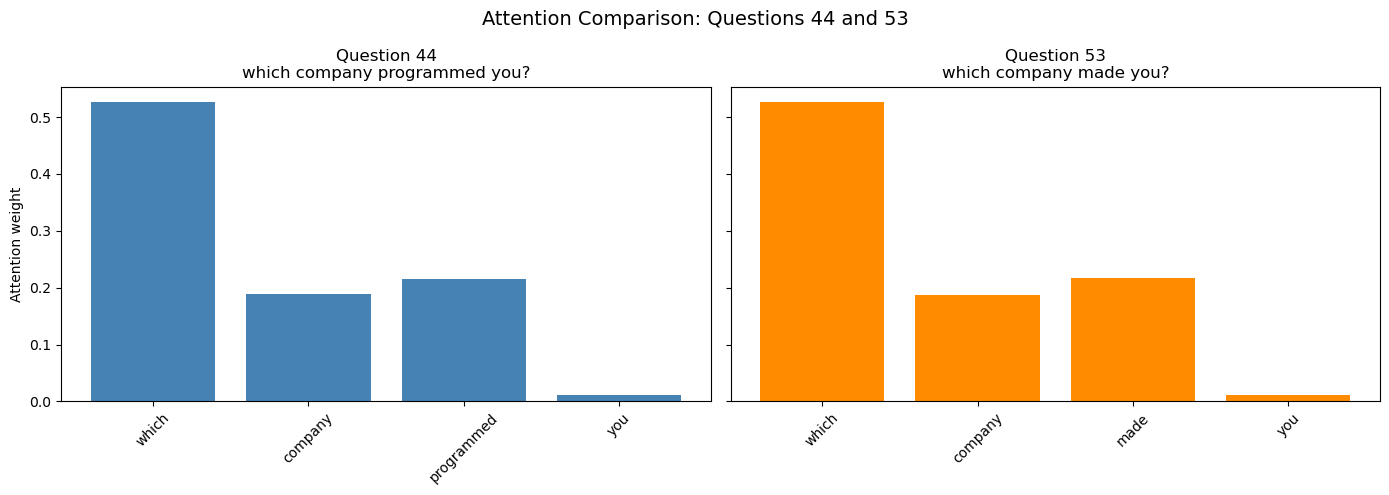

In [8]:
pairs = [[25 , 27],[47 , 50],[44 , 53]]

for q_1 , q_2 in pairs:
    r1, r2 = get_attention(q_1), get_attention(q_2)
    
    print("Comparison of two similar questions:")

    for i, r in [(q_1, r1), (q_2, r2)]:
        print(f"Question {i}: {r['question']}")
        print(f"  answer_id = {r['answer_id']}, predicted = {r['predicted']}")
        print(f"Highest-attention word: {r['highest_word']} " f"({r['highest_weight']:.4f})\n")
    print()
        
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

    axes[0].bar(r1["words"], r1["attention"], color="steelblue")
    axes[0].set_title(f"Question {q_1}\n{r1['question']}")
    axes[0].set_ylabel("Attention weight")
    axes[0].tick_params(axis="x", rotation=45)

    axes[1].bar(r2["words"], r2["attention"], color="darkorange")
    axes[1].set_title(f"Question {q_2}\n{r2['question']}")
    axes[1].tick_params(axis="x", rotation=45)

    plt.suptitle(f"Attention Comparison: Questions {q_1} and {q_2}", fontsize=14)
    plt.tight_layout()
    plt.show()